In [3]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train_df = pd.read_csv("train_FD001.txt", sep=r"\s+", header=None)
test_df = pd.read_csv("test_FD001.txt", sep=r"\s+", header=None)
rul_df = pd.read_csv("RUL_FD001.txt", header=None)

In [5]:
print("Training Shape :", train_df.shape)
print("Testing Shape  :", test_df.shape)
print("RUL Shape      :", rul_df.shape)

Training Shape : (20631, 26)
Testing Shape  : (13096, 26)
RUL Shape      : (100, 1)


In [6]:
columns = ['Engine_ID', 'Cycle']

columns += ['Setting_1', 'Setting_2', 'Setting_3']

columns += [f'Sensor_{i}' for i in range(1,22)]

train_df.columns = columns
test_df.columns = columns

In [7]:
train_df.head()

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Engine_ID  20631 non-null  int64  
 1   Cycle      20631 non-null  int64  
 2   Setting_1  20631 non-null  float64
 3   Setting_2  20631 non-null  float64
 4   Setting_3  20631 non-null  float64
 5   Sensor_1   20631 non-null  float64
 6   Sensor_2   20631 non-null  float64
 7   Sensor_3   20631 non-null  float64
 8   Sensor_4   20631 non-null  float64
 9   Sensor_5   20631 non-null  float64
 10  Sensor_6   20631 non-null  float64
 11  Sensor_7   20631 non-null  float64
 12  Sensor_8   20631 non-null  float64
 13  Sensor_9   20631 non-null  float64
 14  Sensor_10  20631 non-null  float64
 15  Sensor_11  20631 non-null  float64
 16  Sensor_12  20631 non-null  float64
 17  Sensor_13  20631 non-null  float64
 18  Sensor_14  20631 non-null  float64
 19  Sensor_15  20631 non-null  float64
 20  Sensor

In [9]:
train_df.describe()

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,1.776400e-15,...,0.737553,0.071919,19.076176,0.037505,1.387812e-17,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


In [10]:
print(train_df.isnull().sum())

Engine_ID    0
Cycle        0
Setting_1    0
Setting_2    0
Setting_3    0
Sensor_1     0
Sensor_2     0
Sensor_3     0
Sensor_4     0
Sensor_5     0
Sensor_6     0
Sensor_7     0
Sensor_8     0
Sensor_9     0
Sensor_10    0
Sensor_11    0
Sensor_12    0
Sensor_13    0
Sensor_14    0
Sensor_15    0
Sensor_16    0
Sensor_17    0
Sensor_18    0
Sensor_19    0
Sensor_20    0
Sensor_21    0
dtype: int64


In [11]:
print(test_df.isnull().sum())

Engine_ID    0
Cycle        0
Setting_1    0
Setting_2    0
Setting_3    0
Sensor_1     0
Sensor_2     0
Sensor_3     0
Sensor_4     0
Sensor_5     0
Sensor_6     0
Sensor_7     0
Sensor_8     0
Sensor_9     0
Sensor_10    0
Sensor_11    0
Sensor_12    0
Sensor_13    0
Sensor_14    0
Sensor_15    0
Sensor_16    0
Sensor_17    0
Sensor_18    0
Sensor_19    0
Sensor_20    0
Sensor_21    0
dtype: int64


In [12]:
print("Training Duplicates:", train_df.duplicated().sum())

print("Testing Duplicates:", test_df.duplicated().sum())

Training Duplicates: 0
Testing Duplicates: 0


In [13]:
max_cycle = train_df.groupby("Engine_ID")["Cycle"].max().reset_index()

max_cycle.columns = ["Engine_ID","Max_Cycle"]

In [14]:
train_df = train_df.merge(max_cycle,on="Engine_ID")

In [15]:
train_df["RUL"] = train_df["Max_Cycle"] - train_df["Cycle"]

In [ ]:

RUL_CAP = 125
train_df["RUL"] = train_df["RUL"].clip(upper=RUL_CAP)


In [17]:
train_df.drop("Max_Cycle",axis=1,inplace=True)

In [18]:
train_df.head()

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125


In [19]:
print("Training Engines:", train_df["Engine_ID"].nunique())

print("Testing Engines:", test_df["Engine_ID"].nunique())

Training Engines: 100
Testing Engines: 100


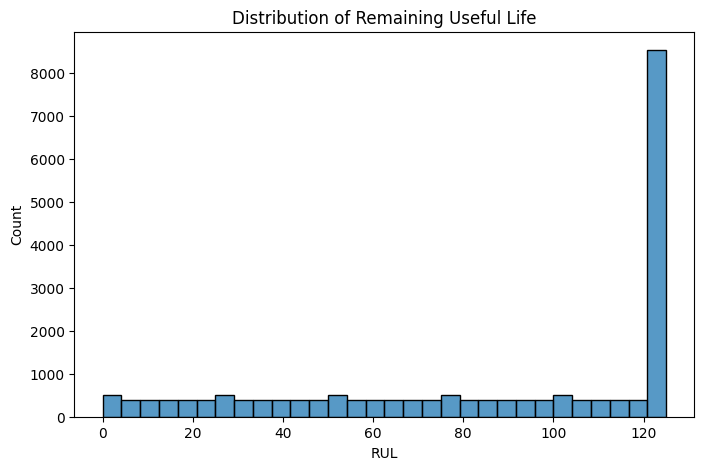

In [20]:
plt.figure(figsize=(8,5))

sns.histplot(train_df["RUL"], bins=30)

plt.title("Distribution of Remaining Useful Life")

plt.show()

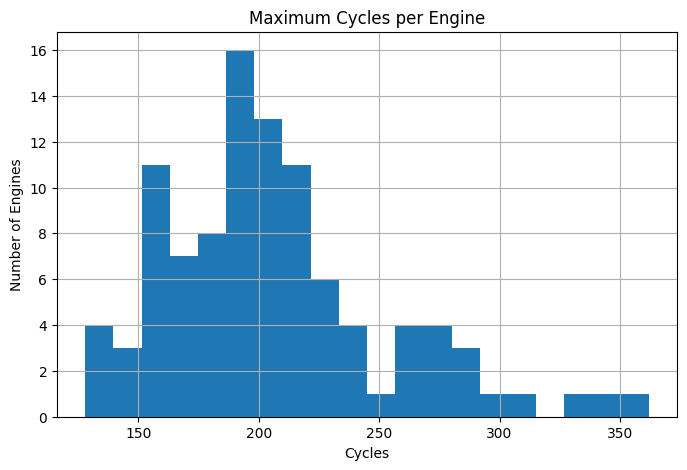

In [21]:
engine_cycles = train_df.groupby("Engine_ID")["Cycle"].max()

plt.figure(figsize=(8,5))

engine_cycles.hist(bins=20)

plt.title("Maximum Cycles per Engine")

plt.xlabel("Cycles")

plt.ylabel("Number of Engines")

plt.show()

In [22]:
variance = train_df.var(numeric_only=True)

variance.sort_values()

Sensor_1     0.000000e+00
Setting_3    0.000000e+00
Sensor_10    0.000000e+00
Sensor_18    0.000000e+00
Sensor_19    0.000000e+00
Sensor_16    1.926023e-34
Sensor_5     3.155597e-30
Setting_2    8.588541e-08
Sensor_6     1.929279e-06
Setting_1    4.784340e-06
Sensor_15    1.406628e-03
Sensor_8     5.038938e-03
Sensor_13    5.172330e-03
Sensor_21    1.171825e-02
Sensor_20    3.266927e-02
Sensor_11    7.133568e-02
Sensor_2     2.500533e-01
Sensor_12    5.439850e-01
Sensor_7     7.833883e-01
Sensor_17    2.398667e+00
Sensor_3     3.759099e+01
Sensor_4     8.101089e+01
Sensor_14    3.639005e+02
Sensor_9     4.876536e+02
Engine_ID    8.542545e+02
RUL          1.736697e+03
Cycle        4.744591e+03
dtype: float64

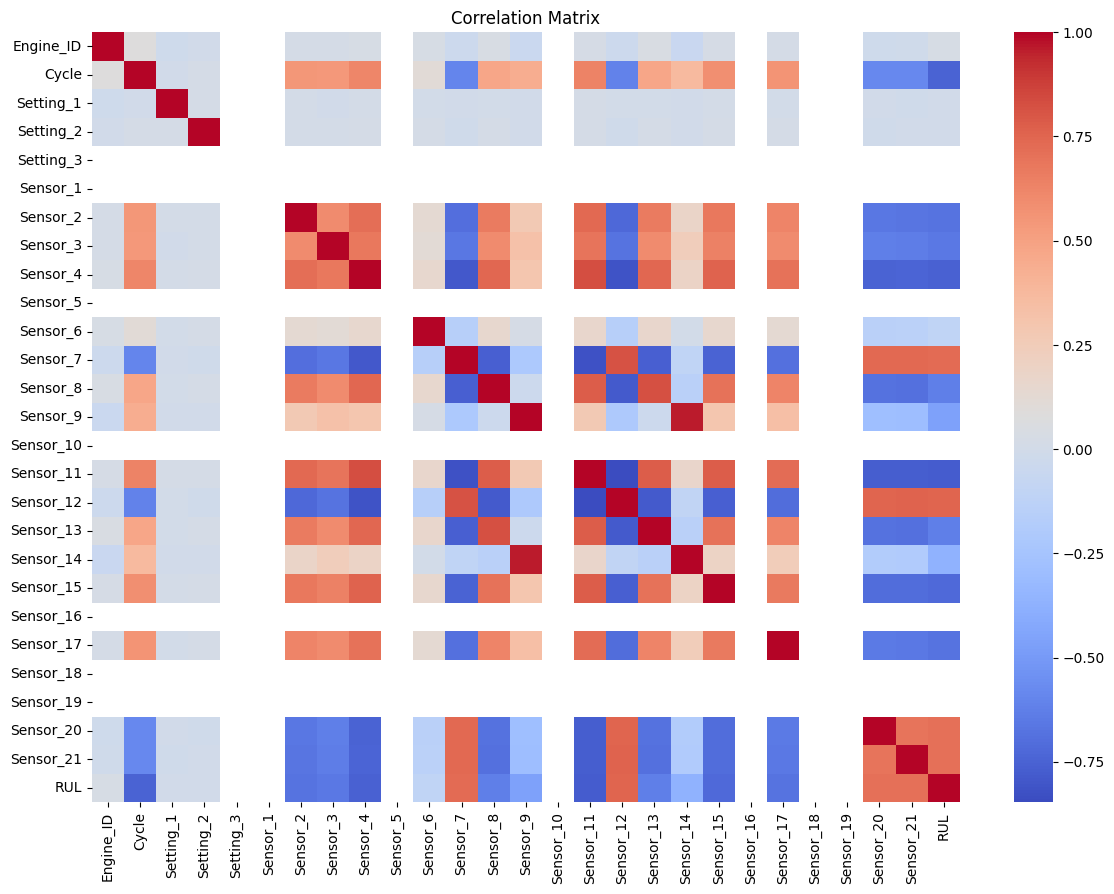

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14,10))

sns.heatmap(train_df.corr(), cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

In [24]:
from sklearn.preprocessing import MinMaxScaler

feature_cols = train_df.columns.difference(
    ["Engine_ID", "Cycle", "RUL"]
)

scaler = MinMaxScaler()

train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])

test_df[feature_cols] = scaler.transform(test_df[feature_cols])

In [25]:
train_df.head()

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21,RUL
0,1,1,0.459770,0.166667,0.0,0.0,0.183735,0.406802,0.309757,0.0,...,0.205882,0.199608,0.363986,0.0,0.333333,0.0,0.0,0.713178,0.724662,125
1,1,2,0.609195,0.250000,0.0,0.0,0.283133,0.453019,0.352633,0.0,...,0.279412,0.162813,0.411312,0.0,0.333333,0.0,0.0,0.666667,0.731014,125
2,1,3,0.252874,0.750000,0.0,0.0,0.343373,0.369523,0.370527,0.0,...,0.220588,0.171793,0.357445,0.0,0.166667,0.0,0.0,0.627907,0.621375,125
3,1,4,0.540230,0.500000,0.0,0.0,0.343373,0.256159,0.331195,0.0,...,0.294118,0.174889,0.166603,0.0,0.333333,0.0,0.0,0.573643,0.662386,125
4,1,5,0.390805,0.333333,0.0,0.0,0.349398,0.257467,0.404625,0.0,...,0.235294,0.174734,0.402078,0.0,0.416667,0.0,0.0,0.589147,0.704502,125


In [27]:
train_df.describe()

,Engine_ID,Cycle,Setting_1,Setting_2,Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000,20631.0,...,20631.000000,20631.000000,20631.000000,20631.0,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,0.499490,0.501959,0.0,0.0,0.443052,0.424746,0.450435,0.0,...,0.317871,0.226095,0.451118,0.0,0.434221,0.0,0.0,0.524241,0.546127,86.829286
std,29.227633,68.880990,0.125708,0.244218,0.0,0.0,0.150618,0.133664,0.151935,0.0,...,0.105763,0.098442,0.144306,0.0,0.129064,0.0,0.0,0.140114,0.149476,41.673699
min,1.000000,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000
25%,26.000000,52.000000,0.413793,0.333333,0.0,0.0,0.335843,0.331807,0.339467,0.0,...,0.235294,0.171870,0.346287,0.0,0.333333,0.0,0.0,0.434109,0.452361,51.000000
50%,52.000000,104.000000,0.500000,0.500000,0.0,0.0,0.430723,0.415522,0.435348,0.0,...,0.308824,0.209516,0.438630,0.0,0.416667,0.0,0.0,0.534884,0.557443,103.000000
75%,77.000000,156.000000,0.586207,0.750000,0.0,0.0,0.539157,0.508829,0.545324,0.0,...,0.382353,0.249613,0.541362,0.0,0.500000,0.0,0.0,0.627907,0.652582,125.000000
max,100.000000,362.000000,1.000000,1.000000,0.0,0.0,1.000000,1.000000,1.000000,0.0,...,1.000000,1.000000,1.000000,0.0,1.000000,0.0,0.0,1.000000,1.000000,125.000000


**Before running this cell:** back up your current `Dataset/processed_train.csv` (e.g. rename it to `processed_train_uncapped.csv`) if you want to keep the uncapped baseline numbers you already have. This cell will overwrite `processed_train.csv` with the capped version, and every downstream notebook (`baseline.ipynb`, `dropout.ipynb`, `dropout_missing.ipynb`) reads from that same filename, so no path changes are needed anywhere else -- just re-run them top to bottom after this.

In [28]:
train_df.to_csv("processed_train.csv", index=False)
test_df.to_csv("processed_test.csv", index=False)